# Cats vs. Dogs: CNN Optimization with Grid Search

**Problem:** classify cat and dog images using **transfer learning** with an **ImageNet-pretrained ResNet18** whose last layer is replaced for 2 classes.

**Central question:** which hyperparameter combination **generalizes best**, rather than which one memorizes the training set best?

| Step | What is done |
|---|---|
| 1. Data | Kaggle dataset, **fixed and stratified** 70% train / 15% validation / 15% test split |
| 2. Model | Pretrained ResNet18 + new head (Dropout -> Linear 2), with a choice of **how many convolutional layers are fine-tuned** |
| 3. Grid search | learning rate x batch size x fine-tuned layers x dropout x optimizer, using **only train + validation** |
| 4. Selection | Best configuration = **lowest validation loss** (not highest training accuracy) |
| 5. Evaluation | Loss and accuracy on train, validation and test + learning curves |

> The **test set is used only once**, at the very end, after the model has already been chosen.

**Recommended environment:** a GPU (e.g. Google Colab T4, or a local CUDA machine). On CPU, reduce `GRID_TRAIN_FRACTION` and `PARAM_GRID`.

### Design decisions
* The network returns **raw logits** and the loss is `nn.CrossEntropyLoss` (which applies `log_softmax` internally).
* ImageNet **normalization** (mean/std used in pre-training).
* Frozen layers keep their **BatchNorm in `eval` mode**, preserving ImageNet statistics.
* Augmentation is applied **only to the training set**; validation and test are deterministic.
* The split is stratified and fixed (seeded); the grid search uses one fixed validation set (no `GridSearchCV`).

## 1. Environment setup

In [6]:
# Install the only extra dependency (skip if already installed)
%pip install -q kagglehub

Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: C:\Users\sanch\anaconda3\python.exe
Python version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]


In [4]:
import torch
import torchvision

print(torch.__version__)
print(torchvision.__version__)
print(torch.cuda.is_available())

2.15.0+cpu
0.29.2+cpu
False


In [5]:
# Standard library
import copy
import json
import random
import shutil
import time
from pathlib import Path

# Third-party libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from PIL import Image
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import ParameterGrid, train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models
from torchvision.transforms import v2

# Select the compute device (GPU if available)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")


def seed_everything(seed: int):
    """Fix all random seeds for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


SEED = 42
seed_everything(SEED)

Device: cpu | CPU


### Experiment parameters

Everything that controls the cost of the experiment lives here. On a T4 GPU with the default values, the full grid (32 configurations) takes roughly **1 to 2 hours**.

> If you change `IMG_SIZE`, `GRID_TRAIN_FRACTION` or the epochs, delete `grid_search.csv` first: resuming identifies each configuration only by its `PARAM_GRID` hyperparameters.

In [6]:
# --- Data ---
KAGGLE_DATASET = "jakupymeraj/cats-and-dogs-image-dataset"
DATA_DIR = None          # None = download from Kaggle; or a local path with one sub-folder per class
IMG_SIZE = 224           # ResNet18 ImageNet pre-training resolution
SPLIT = (0.70, 0.15, 0.15)  # train / validation / test

# --- Model ---
PRETRAINED = True        # use ResNet18_Weights.DEFAULT (ImageNet)

# --- Grid search ---
PARAM_GRID = {
    "lr":         [1e-3, 1e-4],
    "batch_size": [32, 64],
    "fine_tune":  ["fc", "layer4"],  # "fc" = only the new output layer; "layer4" = + last conv block
    "dropout":    [0.0, 0.5],        # dropout before the output layer
    "optimizer":  ["adam", "sgd"],
}
GRID_MAX_EPOCHS = 5         # max epochs per configuration during the grid
GRID_PATIENCE = 2           # early stopping: epochs without validation-loss improvement
GRID_TRAIN_FRACTION = 1.0   # fraction of the training set used in the grid (e.g. 0.5 to speed up)

# --- Final training of the best model ---
FINAL_MAX_EPOCHS = 15
FINAL_PATIENCE = 4

# --- Outputs ---
OUT_DIR = Path("results_transfer_learning")
OUT_DIR.mkdir(exist_ok=True)
GRID_CSV = OUT_DIR / "grid_search.csv"   # saved after every configuration (allows resuming)

print(f"{len(ParameterGrid(PARAM_GRID))} configurations in the grid")

32 configurations in the grid


## 2. Data

### 2.1 Download and inventory

The Kaggle dataset ships split into `training_set` and `test_set`. We **merge everything** and redo the 70/15/15 split from scratch to get the exact proportions and a separate validation set.

In [7]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Download the dataset (or use the local folder)
if DATA_DIR is None:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download(KAGGLE_DATASET)
DATA_DIR = Path(DATA_DIR)
print("Data at:", DATA_DIR)


def label_from_path(p: Path):
    """Infer the class from the parent folder name (cats/dogs, cat/dog, Cat/Dog...)."""
    name = p.parent.name.lower()
    if name.startswith("cat"):
        return "cat"
    if name.startswith("dog"):
        return "dog"
    return None


# Build a dataframe with one row per image
files = [p for p in DATA_DIR.rglob("*") if p.suffix.lower() in IMG_EXTS]
df = pd.DataFrame({"path": [str(p) for p in files], "label": [label_from_path(p) for p in files]})
df = df.dropna().drop_duplicates("path").sort_values("path").reset_index(drop=True)

# Encode classes as integers
CLASSES = sorted(df["label"].unique())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
df["y"] = df["label"].map(CLASS_TO_IDX)

print(f"{len(df)} images | classes: {CLASSES}")
df["label"].value_counts()

100%|██████████| 217M/217M [08:37<00:00, 441kB/s]  

Extracting files...


Data at: C:\Users\sanch\.cache\kagglehub\datasets\jakupymeraj\cats-and-dogs-image-dataset\versions\1
10000 images | classes: ['cat', 'dog']


label
cat    5000
dog    5000
Name: count, dtype: int64

### 2.2 Fixed, stratified split: 70% / 15% / 15%

The split is done **once**, with a fixed seed, and saved to CSV. Every grid configuration uses exactly the same sets, so the comparison is fair.

In [8]:
train_frac, val_frac, test_frac = SPLIT

# First carve out train, then split the remainder into validation and test
df_train, df_tmp = train_test_split(df, test_size=val_frac + test_frac, stratify=df["y"], random_state=SEED)
df_val, df_test = train_test_split(df_tmp, test_size=test_frac / (val_frac + test_frac),
                                   stratify=df_tmp["y"], random_state=SEED)

splits = {"train": df_train, "validation": df_val, "test": df_test}
pd.concat([d.assign(split=k) for k, d in splits.items()]).to_csv(OUT_DIR / "split.csv", index=False)

# Summary of size and class balance per split
summary = pd.DataFrame({
    k: {"images": len(d), "% of total": f"{len(d) / len(df):.1%}",
        **{f"% {c}": f"{(d['label'] == c).mean():.1%}" for c in CLASSES}}
    for k, d in splits.items()
}).T
summary

,images,% of total,% cat,% dog
train,7000,70.0%,50.0%,50.0%
validation,1500,15.0%,50.0%,50.0%
test,1500,15.0%,50.0%,50.0%


### 2.3 Preloading images into memory

Decoding JPEGs every epoch dominates training time. Since the grid trains dozens of models, each image is read **once**, resized to `IMG_SIZE` and stored as a `uint8` tensor. At 224 px each image takes ~150 KB, so 10k images use ~1.5 GB of RAM.

In [9]:
def load_images(paths, size):
    """Read, convert and resize images into one uint8 tensor. Corrupted files are dropped."""
    out = torch.empty((len(paths), 3, size, size), dtype=torch.uint8)
    ok = np.ones(len(paths), dtype=bool)
    for i, p in enumerate(paths):
        try:
            img = Image.open(p).convert("RGB").resize((size, size), Image.BILINEAR)
            out[i] = torch.from_numpy(np.array(img)).permute(2, 0, 1)
        except Exception as e:
            ok[i] = False
            print("Skipping", p, "->", e)
    return out[torch.from_numpy(ok)], ok


cache = {}  # split name -> (images tensor, labels tensor)
t0 = time.time()
for name, d in splits.items():
    x, ok = load_images(d["path"].tolist(), IMG_SIZE)
    cache[name] = (x, torch.tensor(d["y"].values[ok], dtype=torch.long))
    print(f"{name:10s} {tuple(x.shape)}")
print(f"Loaded in {time.time() - t0:.0f}s")

train      (7000, 3, 224, 224)
validation (1500, 3, 224, 224)
test       (1500, 3, 224, 224)
Loaded in 121s


### 2.4 Transforms and data loaders

* **Train:** light augmentation (horizontal flip, small rotation/translation, brightness/contrast jitter).
* **Validation and test:** only conversion and normalization, no randomness.
* **ImageNet normalization**, the same used to pre-train ResNet18.

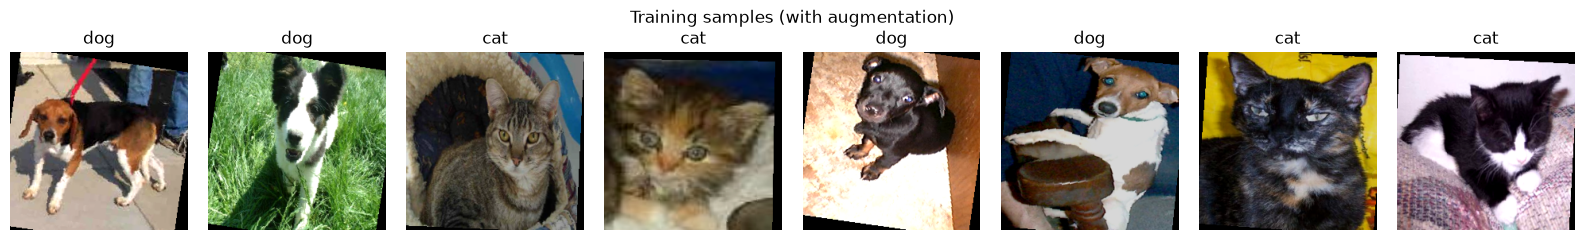

In [11]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet statistics

# Training transform: augmentation + normalization
train_tf = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomAffine(degrees=10, translate=(0.05, 0.05)),
    v2.ColorJitter(brightness=0.2, contrast=0.2),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])

# Evaluation transform: deterministic, normalization only
eval_tf = v2.Compose([
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])


class TensorImageDataset(Dataset):
    """Dataset over in-memory uint8 tensors, applying a transform on access."""

    def __init__(self, x, y, transform):
        self.x, self.y, self.transform = x, y, transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.transform(self.x[i]), self.y[i]


def make_loader(split, transform, batch_size, shuffle, fraction=1.0, seed=SEED):
    """Build a DataLoader for a split."""

    x, y = cache[split]

    if fraction < 1.0:
        idx, _ = train_test_split(
            np.arange(len(y)),
            train_size=fraction,
            stratify=y.numpy(),
            random_state=seed
        )
        x, y = x[idx], y[idx]

    g = torch.Generator().manual_seed(seed)

    return DataLoader(
        TensorImageDataset(x, y, transform),
        batch_size=batch_size,
        shuffle=shuffle,
        generator=g,
        num_workers=0,  # Alteração principal
        pin_memory=DEVICE.type == "cuda"
    )


# Visual sanity check: a few augmented training samples
xb, yb = next(iter(make_loader("train", train_tf, 8, shuffle=True)))

fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))

for ax, img, lab in zip(axes, xb, yb):
    img = (
        img * torch.tensor(STD)[:, None, None]
        + torch.tensor(MEAN)[:, None, None]
    )

    ax.imshow(img.clamp(0, 1).permute(1, 2, 0))
    ax.set_title(CLASSES[lab.item()])
    ax.axis("off")

plt.suptitle("Training samples (with augmentation)")
plt.tight_layout()
plt.show()

## 3. Model: transfer learning with ResNet18

Base model: `models.resnet18(weights=ResNet18_Weights.DEFAULT)`, with the original `fc` layer (1000 ImageNet classes) **replaced by `Dropout -> Linear(512, 2)`**.

The `fine_tune` hyperparameter defines **how many convolutional layers are adjusted**:

| `fine_tune` | Trained layers | Frozen layers |
|---|---|---|
| `"fc"` | only the new output layer | the whole convolutional backbone |
| `"layer4"` | last conv block (`layer4`) + output | `conv1` ... `layer3` |

Frozen layers receive no gradient and their **BatchNorm stays in `eval` mode**. The optimizer only receives the **trainable parameters**.

In [12]:
# Which top-level ResNet blocks are trainable for each fine-tuning mode
TRAINABLE_BLOCKS = {
    "fc":     {"fc"},
    "layer4": {"layer4", "fc"},
    "layer3": {"layer3", "layer4", "fc"},  # available if you want to widen the grid
}


class TransferResNet18(nn.Module):
    """ResNet18 with a new Dropout + Linear head and selective layer freezing."""

    def __init__(self, fine_tune="fc", dropout=0.0, n_classes=2, pretrained=True):
        super().__init__()
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        self.backbone = models.resnet18(weights=weights)

        # Replace the classification head (outputs logits)
        in_features = self.backbone.fc.in_features  # 512
        self.backbone.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_features, n_classes))

        # Freeze everything that is not in the trainable set
        trainable = TRAINABLE_BLOCKS[fine_tune]
        for name, p in self.backbone.named_parameters():
            p.requires_grad = name.split(".")[0] in trainable
        self.frozen = [m for n, m in self.backbone.named_children() if n not in trainable]

    def train(self, mode=True):
        super().train(mode)
        for m in self.frozen:  # keep frozen BatchNorm statistics from ImageNet
            m.eval()
        return self

    def forward(self, x):
        return self.backbone(x)


def build_model(cfg):
    return TransferResNet18(cfg["fine_tune"], cfg["dropout"], len(CLASSES), PRETRAINED).to(DEVICE)


def build_optimizer(cfg, model):
    """Create the optimizer over trainable parameters only."""
    params = [p for p in model.parameters() if p.requires_grad]
    if cfg["optimizer"] == "adam":
        return torch.optim.Adam(params, lr=cfg["lr"])
    if cfg["optimizer"] == "sgd":
        return torch.optim.SGD(params, lr=cfg["lr"], momentum=0.9)
    raise ValueError(cfg["optimizer"])


# Report the number of trainable parameters per fine-tuning mode
for ft in PARAM_GRID["fine_tune"]:
    m = build_model({"fine_tune": ft, "dropout": 0.0})
    total = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"fine_tune={ft:7s}: {trainable:>10,} trainable of {total:,} ({trainable / total:.1%})")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\sanch/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [01:02<00:00, 752kB/s] 


fine_tune=fc     :      1,026 trainable of 11,177,538 (0.0%)
fine_tune=layer4 :  8,394,754 trainable of 11,177,538 (75.1%)


### Training loop with early stopping

* Each epoch: train on the **train** set and measure loss/accuracy on **validation**.
* Keep the weights from the epoch with the **lowest validation loss** and stop after `patience` epochs without improvement.
* Training metrics in the history are running averages (augmentation and dropout on). In the final evaluation the train set is re-evaluated in `eval` mode, under the same conditions as validation and test.

In [13]:
criterion = nn.CrossEntropyLoss()


def run_epoch(model, loader, optimizer=None):
    """Run one pass over a loader. Trains if an optimizer is given, otherwise evaluates."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n


def fit(cfg, max_epochs, patience, train_fraction=1.0, verbose=False):
    """Train one configuration with early stopping on validation loss.
    Returns the model (best weights), the per-epoch history and the best-epoch metrics."""
    seed_everything(SEED)
    model = build_model(cfg)
    optimizer = build_optimizer(cfg, model)
    train_loader = make_loader("train", train_tf, cfg["batch_size"], shuffle=True, fraction=train_fraction)
    val_loader = make_loader("validation", eval_tf, 256, shuffle=False)

    history, best = [], {"val_loss": float("inf")}
    best_state, wait = None, 0
    for epoch in range(1, max_epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader)

        if not np.isfinite(tr_loss):  # diverged (e.g. learning rate too high)
            print("  non-finite loss, stopping this configuration")
            break

        history.append({"epoch": epoch, "train_loss": tr_loss, "train_acc": tr_acc,
                        "val_loss": va_loss, "val_acc": va_acc, "sec": time.time() - t0})
        if verbose:
            print(f"  epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
                  f"val loss {va_loss:.4f} acc {va_acc:.3f} | {time.time() - t0:.0f}s")

        # Early stopping bookkeeping
        if va_loss < best["val_loss"]:
            best = history[-1].copy()
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)  # restore the best epoch
    return model, pd.DataFrame(history), best

In [20]:
print(TRAINABLE_BLOCKS)

{'fc': {'fc'}, 'layer4': {'fc', 'layer4'}, 'layer3': {'layer3', 'layer4', 'fc'}}


In [21]:
# ============================================================
# MANUAL TRAINING — ResNet18
# ============================================================

cfg = {
    "lr": 1e-4,
    "batch_size": 32,
    "weight_decay": 1e-4,
    "dropout": 0.3,
    "optimizer": "adam",
    "fine_tune": "fc"
}

t0 = time.time()

model, hist, best = fit(
    cfg=cfg,
    max_epochs=10,
    patience=3,
    train_fraction=1.0,
    verbose=True
)

print("\n===== TRAINING RESULTS =====")
print(f"Best epoch: {best['epoch']}")
print(f"Training loss: {best['train_loss']:.4f}")
print(f"Training accuracy: {best['train_acc']:.4f}")
print(f"Validation loss: {best['val_loss']:.4f}")
print(f"Validation accuracy: {best['val_acc']:.4f}")
print(f"Total time: {(time.time() - t0) / 60:.2f} minutes")

  epoch  1 | train loss 0.5157 acc 0.739 | val loss 0.2389 acc 0.946 | 951s
  epoch  2 | train loss 0.2177 acc 0.931 | val loss 0.1458 acc 0.961 | 921s
  epoch  3 | train loss 0.1478 acc 0.953 | val loss 0.1149 acc 0.965 | 1146s
  epoch  4 | train loss 0.1226 acc 0.961 | val loss 0.0986 acc 0.969 | 761s
  epoch  5 | train loss 0.1084 acc 0.965 | val loss 0.0863 acc 0.974 | 734s
  epoch  6 | train loss 0.0986 acc 0.966 | val loss 0.0804 acc 0.975 | 736s


KeyboardInterrupt: 

# 4. Grid search

Each combination in PARAM_GRID is trained on train and evaluated on validation. The test set does not take part.

Each result is written to results_transfer_learning/grid_search.csv as soon as it finishes. If the session drops, just re-run the cell: finished configurations are skipped.

In [22]:
grid = list(ParameterGrid(PARAM_GRID))
config_key = lambda c: json.dumps({k: c[k] for k in sorted(PARAM_GRID)}, sort_keys=True)

# Resume support: load already-finished configurations
done = pd.read_csv(GRID_CSV) if GRID_CSV.exists() else pd.DataFrame()
done_keys = set(done["config"]) if len(done) else set()

t_grid = time.time()
for i, cfg in enumerate(grid, 1):
    if config_key(cfg) in done_keys:
        continue
    print(f"[{i}/{len(grid)}] {cfg}")
    t0 = time.time()
    _, hist, best = fit(cfg, GRID_MAX_EPOCHS, GRID_PATIENCE, train_fraction=GRID_TRAIN_FRACTION)

    # Configuration diverged before any valid epoch
    if best["val_loss"] == float("inf"):
        best = {"epoch": 0, "train_loss": np.nan, "train_acc": np.nan, "val_loss": np.nan, "val_acc": np.nan}

    row = {**cfg, "config": config_key(cfg), "best_epoch": best["epoch"], "epochs_run": len(hist),
           "train_loss": best["train_loss"], "train_acc": best["train_acc"],
           "val_loss": best["val_loss"], "val_acc": best["val_acc"],
           "max_train_acc": hist["train_acc"].max() if len(hist) else np.nan,
           "minutes": (time.time() - t0) / 60}
    print(f"   -> val loss {row['val_loss']:.4f} | val acc {row['val_acc']:.3f} | "
          f"best epoch {row['best_epoch']} | {row['minutes']:.1f} min")

    # Persist after every configuration
    done = pd.concat([done, pd.DataFrame([row])], ignore_index=True)
    done.to_csv(GRID_CSV, index=False)

print(f"Grid finished in {(time.time() - t_grid) / 60:.1f} min")

[1/32] {'batch_size': 32, 'dropout': 0.0, 'fine_tune': 'fc', 'lr': 0.001, 'optimizer': 'adam'}


KeyboardInterrupt: 

### 4.1 Configuration ranking

**Selection criterion:** lowest **validation loss** (ties broken by validation accuracy).
`gap` = train accuracy - validation accuracy at the chosen epoch. A large gap signals *overfitting*.

In [ ]:
results = pd.read_csv(GRID_CSV)
results = results[results["config"].isin({config_key(c) for c in grid})].copy()
results["gap"] = results["train_acc"] - results["val_acc"]
results = results.sort_values(["val_loss", "val_acc"], ascending=[True, False]).reset_index(drop=True)
results.index += 1  # rank starts at 1

cols = ["lr", "batch_size", "fine_tune", "dropout", "optimizer",
        "best_epoch", "train_loss", "val_loss", "train_acc", "val_acc", "gap"]
fmt = {"lr": "{:.0e}", "train_loss": "{:.4f}", "val_loss": "{:.4f}",
       "train_acc": "{:.3f}", "val_acc": "{:.3f}", "gap": "{:+.3f}"}
(results[cols].head(10).style.format(fmt)
    .background_gradient(subset=["val_acc"], cmap="Greens")
    .background_gradient(subset=["gap"], cmap="Reds"))

In [ ]:
# Extract the winning configuration (rank 1) with native Python types
best_cfg = {k: results.loc[1, k] for k in PARAM_GRID}
best_cfg = {k: (v.item() if hasattr(v, "item") else v) for k, v in best_cfg.items()}
best_cfg["batch_size"] = int(best_cfg["batch_size"])
best_cfg["dropout"] = float(best_cfg["dropout"])
best_cfg["lr"] = float(best_cfg["lr"])

print("Best hyperparameter combination (lowest validation loss):")
for k, v in best_cfg.items():
    print(f"   {k:13s} = {v}")

### 4.2 Generalization: is the best on train also the best on validation?

Each point is one configuration. Points **above the diagonal** (train >> validation) are memorizing the training set.

In [ ]:
by_train = results.sort_values("max_train_acc", ascending=False).iloc[0]  # highest training accuracy
best_row = results.loc[1]                                                  # lowest validation loss

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Left: train vs. validation accuracy per configuration
ax[0].scatter(results["val_acc"], results["train_acc"], c=results["gap"], cmap="coolwarm", s=60, edgecolor="k")
lim = [min(results[["train_acc", "val_acc"]].min()) - 0.02, 1.0]
ax[0].plot(lim, lim, "k--", lw=1, label="train = validation")
ax[0].scatter(best_row["val_acc"], best_row["train_acc"], s=250, facecolor="none", edgecolor="green", lw=2.5,
              label="selected (lowest val loss)")
ax[0].scatter(by_train["val_acc"], by_train["train_acc"], s=250, marker="s", facecolor="none", edgecolor="red",
              lw=2.5, label="highest train accuracy")
ax[0].set(xlabel="validation accuracy", ylabel="train accuracy", title="Train vs. validation per configuration")
ax[0].legend(loc="lower right")

# Right: top 15 configurations
top = results.head(15).iloc[::-1]
labels = [f"{r.fine_tune} | {r.optimizer} | lr={r.lr:.0e} | bs={r.batch_size} | do={r.dropout}"
          for r in top.itertuples()]
ax[1].barh(labels, top["val_acc"], color="tab:green", alpha=0.8, label="validation")
ax[1].barh(labels, top["train_acc"], color="none", edgecolor="k", label="train")
ax[1].set(xlabel="accuracy", title="Top 15 configurations (by validation loss)",
          xlim=(max(0.4, top[["val_acc", "train_acc"]].min().min() - 0.05), 1.0))
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig(OUT_DIR / "generalization.png", dpi=150)
plt.show()

# Side-by-side comparison of the two candidates
comparison = pd.DataFrame([best_row, by_train], index=["Selected (lowest val loss)", "Highest train accuracy"])
comparison[["fine_tune", "optimizer", "lr", "batch_size", "dropout", "max_train_acc", "val_acc", "val_loss"]]

### 4.3 Effect of each hyperparameter

Mean accuracy and validation loss grouped by each hyperparameter (averaged over all combinations of the others).

In [ ]:
fig, axes = plt.subplots(1, len(PARAM_GRID), figsize=(4 * len(PARAM_GRID), 3.6), sharey=True)
for ax, hp in zip(axes, PARAM_GRID):
    g = results.groupby(hp)[["val_acc", "train_acc"]].mean()
    x = np.arange(len(g))
    ax.bar(x - 0.2, g["train_acc"], 0.4, label="train", color="tab:blue", alpha=0.7)
    ax.bar(x + 0.2, g["val_acc"], 0.4, label="validation", color="tab:green", alpha=0.9)
    ax.set_xticks(x, [f"{v:.0e}" if hp == "lr" else str(v) for v in g.index])
    ax.set_title(hp)
    ax.set_ylim(max(0.4, results[["val_acc", "train_acc"]].min().min() - 0.05), 1.0)
axes[0].set_ylabel("mean accuracy")
axes[0].legend()
plt.suptitle("Average effect of each hyperparameter")
plt.tight_layout()
plt.savefig(OUT_DIR / "hyperparameter_effects.png", dpi=150)
plt.show()

# Numeric table of the same grouping
pd.concat({hp: results.groupby(hp)[["val_loss", "val_acc", "gap"]].mean() for hp in PARAM_GRID}).style.format("{:.3f}")

## 5. Final training of the best model

The winning configuration is trained again, now with more epochs (`FINAL_MAX_EPOCHS`) on the full training set, keeping early stopping on **validation**. The history of this run produces the **learning curves**.

In [ ]:
print("Training:", best_cfg)
best_model, history, best_epoch_info = fit(best_cfg, FINAL_MAX_EPOCHS, FINAL_PATIENCE, verbose=True)

# Save history and model checkpoint
history.to_csv(OUT_DIR / "best_model_history.csv", index=False)
torch.save({"config": best_cfg, "state_dict": best_model.state_dict(), "classes": CLASSES},
           OUT_DIR / "best_model.pt")
print(f"\nBest epoch: {best_epoch_info['epoch']}")

### 5.1 Learning curves

In [ ]:
be = best_epoch_info["epoch"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, metric, title in [(ax[0], "loss", "Loss (CrossEntropy)"), (ax[1], "acc", "Accuracy")]:
    a.plot(history["epoch"], history[f"train_{metric}"], "o-", label="train")
    a.plot(history["epoch"], history[f"val_{metric}"], "o-", label="validation")
    a.axvline(be, color="gray", ls="--", label=f"best epoch ({be})")
    a.set(xlabel="epoch", title=title)
    a.grid(alpha=0.3)
    a.legend()
    a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
cfg_txt = ", ".join(f"{k}={v}" for k, v in best_cfg.items())
plt.suptitle(f"Learning curves of the best model\n{cfg_txt}")
plt.tight_layout()
plt.savefig(OUT_DIR / "learning_curves.png", dpi=150)
plt.show()

## 6. Final evaluation: train vs. validation vs. test

All three sets are evaluated **under the same conditions** (`eval` mode, no augmentation, no dropout). This is the **first and only time** the test set is used.

In [ ]:
final = {}
for split in ["train", "validation", "test"]:
    loader = make_loader(split, eval_tf, 256, shuffle=False)
    loss, acc = run_epoch(best_model, loader)
    final[split] = {"loss": loss, "accuracy": acc, "images": len(loader.dataset)}

final_df = pd.DataFrame(final).T
final_df["images"] = final_df["images"].astype(int)
final_df.to_csv(OUT_DIR / "final_metrics.csv")
display(final_df.style.format({"loss": "{:.4f}", "accuracy": "{:.2%}"}))

# Bar charts of loss and accuracy per split
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
colors = ["tab:blue", "tab:green", "tab:orange"]
for a, m in zip(ax, ["loss", "accuracy"]):
    bars = a.bar(final_df.index, final_df[m], color=colors)
    a.bar_label(bars, fmt="%.2f" if m == "accuracy" else "%.3f")
    a.set_title(m.capitalize())
ax[1].set_ylim(0, 1.05)
plt.suptitle("Best model: performance per split")
plt.tight_layout()
plt.savefig(OUT_DIR / "final_metrics.png", dpi=150)
plt.show()

In [ ]:
# Confusion matrix and per-class report (test set)
best_model.eval()
preds, trues = [], []
with torch.no_grad():
    for x, y in make_loader("test", eval_tf, 256, shuffle=False):
        preds.append(best_model(x.to(DEVICE)).argmax(1).cpu())
        trues.append(y)
preds, trues = torch.cat(preds).numpy(), torch.cat(trues).numpy()

print(classification_report(trues, preds, target_names=CLASSES, digits=3))
ConfusionMatrixDisplay(confusion_matrix(trues, preds), display_labels=CLASSES).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix - test set")
plt.show()

In [ ]:
# Examples of misclassified test images
x_test, y_test = cache["test"]
wrong = np.where(preds != trues)[0][:8]
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(2.2 * len(wrong), 2.6))
    for ax, i in zip(np.atleast_1d(axes), wrong):
        ax.imshow(x_test[i].permute(1, 2, 0))
        ax.set_title(f"true: {CLASSES[trues[i]]}\npred: {CLASSES[preds[i]]}", fontsize=9, color="red")
        ax.axis("off")
    plt.suptitle("Model errors on the test set")
    plt.tight_layout()
    plt.show()
else:
    print("No misclassified test images.")

## 7. Summary

In [ ]:
tr, va, te = final["train"], final["validation"], final["test"]
gap_tv = tr["accuracy"] - va["accuracy"]
gap_vt = va["accuracy"] - te["accuracy"]

print("BEST HYPERPARAMETER COMBINATION")
for k, v in best_cfg.items():
    print(f"  - {k}: {v}")

print(f"\nGrid: {len(results)} configurations | criterion: lowest validation loss")
print("\nBEST MODEL PERFORMANCE")
for s, m in final.items():
    print(f"  - {s:10s} loss = {m['loss']:.4f} | accuracy = {m['accuracy']:.2%}")

print(f"\nTrain - validation gap: {gap_tv:+.2%}")
print(f"Validation - test gap:  {gap_vt:+.2%}")

if by_train["config"] != best_row["config"]:
    print(f"\nThe configuration with the HIGHEST train accuracy ({by_train['max_train_acc']:.2%}) reached "
          f"{by_train['val_acc']:.2%} on validation, versus {best_row['val_acc']:.2%} for the selected one.")
else:
    print("\nIn this experiment, the highest-train-accuracy configuration matched the lowest-validation-loss one.")

if abs(gap_vt) < 0.03:
    print("Validation and test are close: validation was a good estimate of performance on unseen data.")
else:
    print("Validation and test differ by more than 3 p.p.: consider the variance of the validation set.")

### Possible next steps
* Random or Bayesian search (e.g. Optuna) instead of an exhaustive grid.
* Learning-rate scheduler, and different learning rates for backbone and head.
* Larger backbones (ResNet50, EfficientNet).

In [ ]:
# Bundle all outputs into a single zip file for download
shutil.make_archive("results", "zip", OUT_DIR)
print("Created results.zip")